# Binary fraction per metallicity

In this notebook, we're looking at the binary fraction of WRs per metallicity.
We have a population of 100% binaries and are going to look what fraction is in binaries for a constant
star formation history.

## Luminosity WR limit
The WR phases are defined following the metallicity-dependent WR limits in Gilkins et al.


In [56]:
from posydon.utils.common_functions import convert_metallicity_to_string, orbital_separation_from_period
import matplotlib.pyplot as plt
import numpy as np
import cmap

import pickle
from pathlib import Path

data_folder = Path('/Users/max/Documents/projects/WR_population/data/Z-dependent_L_limit')

In [70]:
metallicity = 0.1
met_str = convert_metallicity_to_string(metallicity)
file_path = data_folder / f'WR_phases_Z{met_str}_Zsun.pkl'
with open(file_path, 'rb') as f:
    data = pickle.load(f)
    
S1_WR_data = data['S1_WR_data']
S2_WR_data = data['S2_WR_data']


In [71]:
time_array = []
weight_array = []
state_array = []
key_array = []
period_array = []
separation_array = []

for key in S1_WR_data:
    data = S1_WR_data[key]['data']
    weights = S1_WR_data[key]['weights']
    
    time_array.extend(data['time'].values)
    weight_array.extend(weights.values)
    state_array.extend(data['state'].values)
    key_array.extend([key] * len(data))
    period_array.extend(data['orbital_period'].values)
    sep = orbital_separation_from_period(data['orbital_period'].values,
                                         data['S1_mass'].values,
                                         data['S2_mass'].values)
    
    separation_array.extend(sep)
    
for key in S2_WR_data:
    data = S2_WR_data[key]['data']
    weights = S2_WR_data[key]['weights']
    
    time_array.extend(data['time'].values)
    weight_array.extend(weights.values)
    state_array.extend(data['state'].values)
    key_array.extend([key] * len(data))
    period_array.extend(data['orbital_period'].values)
    sep = orbital_separation_from_period(data['orbital_period'].values,
                                         data['S1_mass'].values,
                                         data['S2_mass'].values)
    separation_array.extend(sep)
    
time_array = np.array(time_array)
weight_array = np.array(weight_array)
state_array = np.array(state_array)
key_array = np.array(key_array)
period_array = np.array(period_array)
separation_array = np.array(separation_array)

Text(0.5, 0, 'Orbital Period (days)')

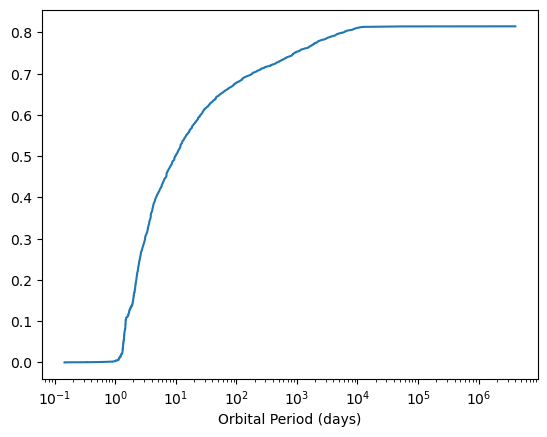

In [72]:
# only 3 keys: 'detached', 'merged', 'disrupted'

binary_mask = (state_array == 'detached') | (state_array == 'RLO1') | (state_array == 'contact') | (state_array == 'RLO2')
single_star_mask = (state_array == 'disrupted') | (state_array == 'merged')

binary_fraction = np.sum(weight_array[binary_mask]) / np.sum(weight_array[single_star_mask | binary_mask])

# Analyze binary fraction among WR phases
# as a function of orbital period
# plot period against, cumulative weight fraction

sorted_indices = np.argsort(period_array[binary_mask])
sorted_periods = period_array[binary_mask][sorted_indices]
sorted_weights = weight_array[binary_mask][sorted_indices]

cumulative_weights = np.cumsum(sorted_weights)
cumulative_weights /= np.sum(weight_array)  # normalize
plt.plot(sorted_periods, cumulative_weights)
plt.xscale('log')
plt.xlabel('Orbital Period (days)')

Text(0, 0.5, 'Cumulative Companion Fraction')

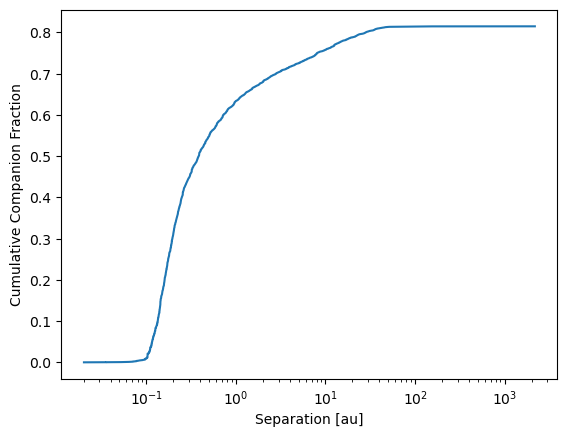

In [73]:
# only 3 keys: 'detached', 'merged', 'disrupted'

binary_mask = (state_array == 'detached') | (state_array == 'RLO1') | (state_array == 'contact') | (state_array == 'RLO2')
single_star_mask = (state_array == 'disrupted') | (state_array == 'merged')

binary_fraction = np.sum(weight_array[binary_mask]) / np.sum(weight_array[single_star_mask | binary_mask])

# Analyze binary fraction among WR phases
# as a function of orbital period
# plot period against, cumulative weight fraction

sorted_indices = np.argsort(separation_array[binary_mask])
sorted_periods = separation_array[binary_mask][sorted_indices]
sorted_weights = weight_array[binary_mask][sorted_indices]

cumulative_weights = np.cumsum(sorted_weights)
cumulative_weights /= np.sum(weight_array)  # normalize
rsun2au = 0.004650476

plt.plot(sorted_periods * rsun2au, cumulative_weights)
plt.xscale('log')
plt.xlabel('Separation [au]')
plt.ylabel('Cumulative Companion Fraction')


## optical depth WR selection



In [147]:
from posydon.utils.common_functions import convert_metallicity_to_string, orbital_separation_from_period
import matplotlib.pyplot as plt
import numpy as np

from cmap import Colormap
import pickle
from pathlib import Path

data_folder = Path('/Users/max/Documents/projects/WR_population/data/optical_depth/')

In [148]:
metallicity = 1.0
met_str = convert_metallicity_to_string(metallicity)
file_path = data_folder / f'WR_phases_Z{met_str}_Zsun.pkl'
with open(file_path, 'rb') as f:
    data = pickle.load(f)
    
S1_WR_data = data['S1_WR_data']
S2_WR_data = data['S2_WR_data']


In [162]:
# hydrogen-poor/free stars
from tqdm import tqdm

WR_types = []
time_array = []
weight_array = []
state_array = []
key_array = []
period_array = []
separation_array = []
Teff_array = []
L_array = []
optical_depth_array = []
surface_H_array = []
surface_He_array = []
mass_array = []
radius_array = []
Mdot_array = []

for key in tqdm(S1_WR_data):
    data = S1_WR_data[key]['data']
    weights = S1_WR_data[key]['weights']
    optical_depth = S1_WR_data[key]['optical_depth']
    
    surface_H = data['S1_surface_h1']
    surface_He = data['S1_surface_he4']
    Teff = 10**calc_Teff(data['S1_log_L'], data['S1_log_R'])
    
    # WR classification
    WN_mask = (surface_H <= 0.4) & (optical_depth >= 1.5)
    WC_mask = (surface_H <= 0.4) & (surface_He < 0.7) & (optical_depth >= 1.5)
    
    WR_types.extend(np.where(WC_mask, 'WC', np.where(WN_mask, 'WN', 'stripped-He')))
    time_array.extend(data['time'].values)
    weight_array.extend(weights)
    state_array.extend(data['state'].values)
    key_array.extend([key] * len(data))
    Teff_array.extend(Teff)
    L_array.extend(10**data['S1_log_L'].values)
    optical_depth_array.extend(optical_depth)
    surface_H_array.extend(surface_H.values)
    surface_He_array.extend(surface_He.values)
    mass_array.extend(data['S1_mass'].values)
    radius_array.extend(10**data['S1_log_R'].values)
    Mdot_array.extend(10**data['S1_lg_mdot'].values)
    
    period_array.extend(data['orbital_period'].values)
    sep = orbital_separation_from_period(data['orbital_period'].values,
                                        data['S1_mass'].values,
                                         data['S2_mass'].values)
    
    separation_array.extend(sep)

WR_types = np.array(WR_types)
time_array = np.array(time_array)
weight_array = np.array(weight_array)
state_array = np.array(state_array)
key_array = np.array(key_array)
period_array = np.array(period_array)
separation_array = np.array(separation_array)
Teff_array = np.array(Teff_array)
L_array = np.array(L_array)
optical_depth_array = np.array(optical_depth_array)
surface_H_array = np.array(surface_H_array)
surface_He_array = np.array(surface_He_array)
mass_array = np.array(mass_array)
radius_array = np.array(radius_array)
Mdot_array = np.array(Mdot_array)


100%|██████████| 52381/52381 [00:12<00:00, 4090.73it/s]


In [178]:
WN_mask = (WR_types == 'WN')
WC_mask = (WR_types == 'WC')
optical_depth_array[WN_mask]

array([ 5.99877327, 18.95556727, 22.78435342, ...,  2.53154837,
        4.05872429,  5.05988518])

In [179]:
# binary fraction per WR type

binary_mask = (state_array == 'detached') | (state_array == 'RLO1') | (state_array == 'contact') | (state_array == 'RLO2')
single_star_mask = (state_array == 'disrupted') | (state_array == 'merged')

WN_mask = WR_types == 'WN'
WC_mask = WR_types == 'WC'
stripped_He_mask = WR_types == 'stripped-He'

WR_binary_fraction = np.sum(weight_array[binary_mask & (WN_mask | WC_mask)]) / np.sum(weight_array[WN_mask | WC_mask])

print("WR binary fraction:", WR_binary_fraction)

print("WN binary fraction:", np.sum(weight_array[binary_mask & WN_mask]) / np.sum(weight_array[WN_mask]))
print("WC binary fraction:", np.sum(weight_array[binary_mask & WC_mask]) / np.sum(weight_array[WC_mask]))



WR binary fraction: 0.7842798484070526
WN binary fraction: 0.8196859981637329
WC binary fraction: 0.7208728435084648


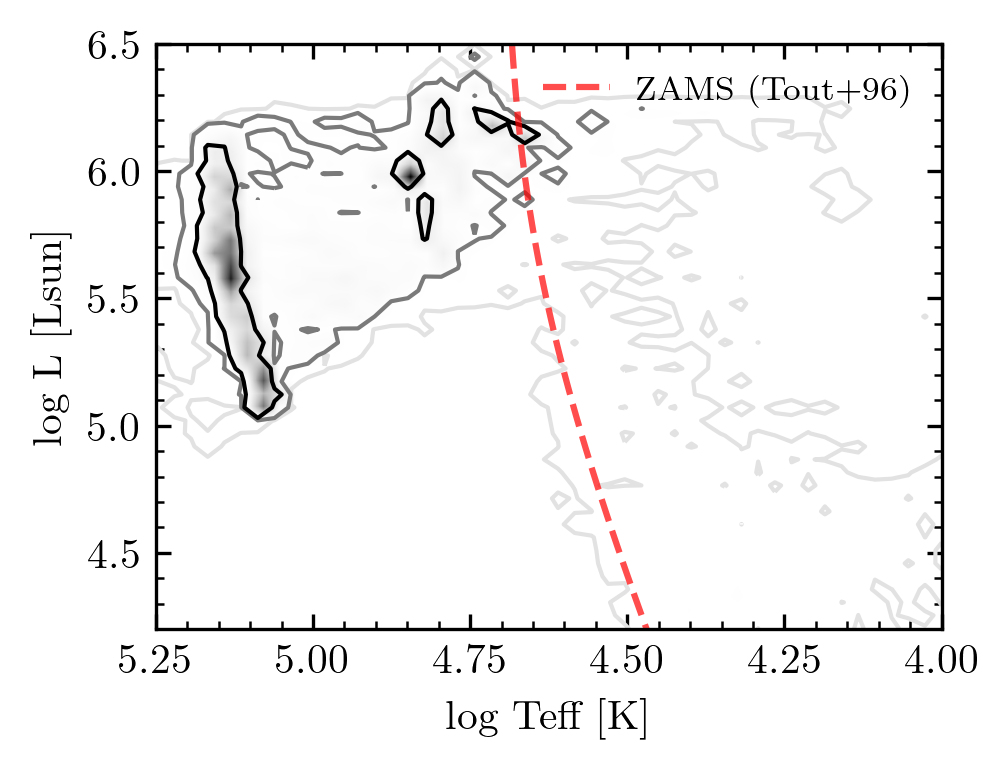

In [177]:
# 2d histogram of Teff and L

cm_grays = Colormap('colorbrewer:Greys')

T_bins = np.linspace(4.0, 5.3, 51)
L_bins = np.linspace(4.0, 6.5, 51)

(H0, xedges, yedges) = \
        np.histogram2d(np.log10(Teff_array)[WN_mask | WC_mask],
                       np.log10(L_array)[WN_mask | WC_mask],
                       weights=weight_array[WN_mask | WC_mask],
                       bins=[T_bins, L_bins])


H0 /= (np.diff(T_bins)[:, None] * np.diff(L_bins))
H0_sorted = np.sort(H0.flatten())[::-1]
H0_cumsum = H0_sorted.cumsum()
H0_total = H0_cumsum[-1]
# Find contour levels for 1, 2, 3 sigma (containing 68.3%, 95.4%, 99.7% of the total)
level0_1 = H0_sorted[np.searchsorted(H0_cumsum, 0.683 * H0_total)]
level0_2 = H0_sorted[np.searchsorted(H0_cumsum, 0.954 * H0_total)]
level0_3 = H0_sorted[np.searchsorted(H0_cumsum, 0.997 * H0_total)]
levels0 = [level0_3, level0_2, level0_1]

plt.imshow(H0.T,
            origin='lower',
            extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]],
            cmap=cm_grays.to_mpl(),
            aspect='auto',
            interpolation='bilinear')

plt.contour(H0.T,
            levels=levels0,
            colors=cm_grays([0.2, 0.6, 1.0]),
            linewidths=[1.0, 1.0, 1.0],
            extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]])

# Add ZAMS and HeMS lines
# ZAMS from Hurley et al. (2000, MNRAS, 315, 543)
# Using their fitting formulas for solar metallicity
# For M in range ~1-120 Msun, compute ZAMS L and Teff
M_zams = np.logspace(0.7, 2.5, 100) 

L_zams = tout_L_ZAMS(M_zams)
R_zams = tout_R_ZAMS(M_zams)

# Hurley et al. (2000) for ZAMS Teff (derived from their radius formula)
# log(Teff) approximation for MS stars
log_Teff_zams = calc_Teff(np.log10(L_zams), np.log10(R_zams))
log_L_zams = np.log10(L_zams)

plt.plot(log_Teff_zams, log_L_zams, 'r--', linewidth=1.5, label='ZAMS (Tout+96)', alpha=0.7)

plt.xlim(5.25, 4.0)
plt.ylim(4.2, 6.5)
plt.xlabel('log Teff [K]')
plt.ylabel('log L [Lsun]')
plt.legend(loc='upper right')


Text(0, 0.5, 'Cumulative Companion Fraction')

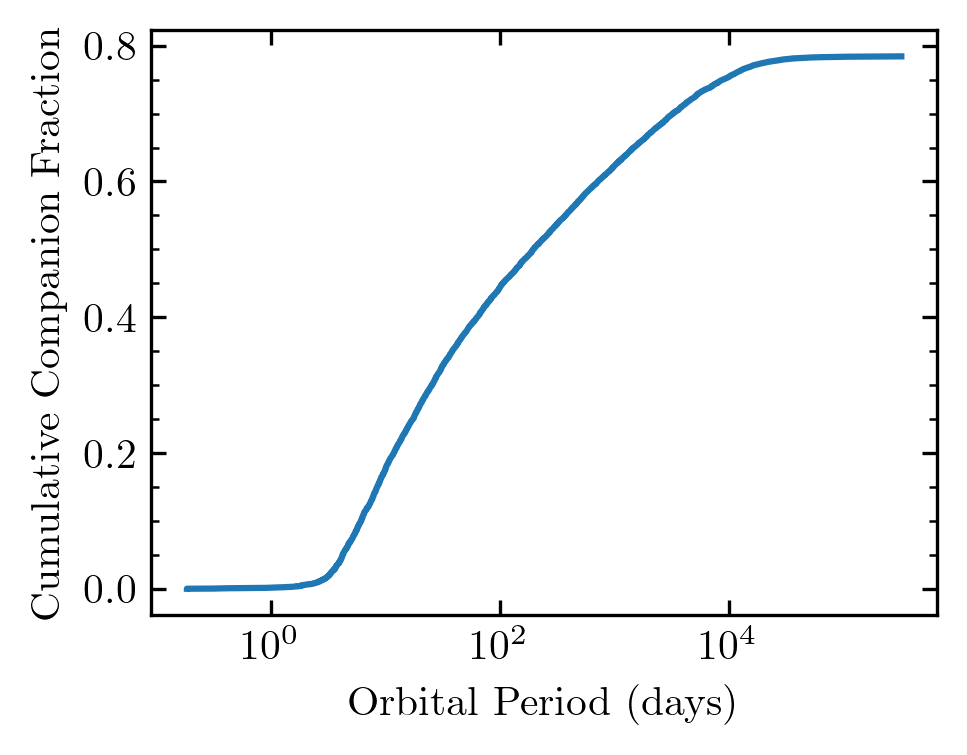

In [167]:
# Period distribution of WR binaries
sorted_indices = np.argsort(period_array[binary_mask & (WN_mask | WC_mask)])
sorted_periods = period_array[binary_mask & (WN_mask | WC_mask)][sorted_indices]
sorted_weights = weight_array[binary_mask & (WN_mask | WC_mask)][sorted_indices]

cumulative_weights = np.cumsum(sorted_weights)
cumulative_weights /= np.sum(weight_array[(WN_mask | WC_mask)])  # normalize
plt.plot(sorted_periods, cumulative_weights)
plt.xscale('log')
plt.xlabel('Orbital Period (days)')
plt.ylabel('Cumulative Companion Fraction')